# 02 · Exploratory data analysis

**Question:** what do the cries look like, and do the 8 classes actually differ in ways we can
measure and explain?

This notebook uses the 479 clean clips from notebook 01, all converted to 8 kHz mono. It looks at
a handful of descriptors a person can interpret (pitch, how much of the clip is crying, how the
crying is broken into bursts) before notebook 03 builds the larger feature set for the models.

One rule runs through the whole notebook: **one baby counts once.** 116 babies contribute
several clips, and clips of the same baby are much more alike than clips of different babies
(section 6 measures this). So class comparisons use one value per baby, not one per clip.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal, mannwhitneyu

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from src import viz
from src.audio import CLASSES, DATA_DIR, SR, load_audio, load_clean_index
from src.descriptors import (FRAME, HOP, cry_mask, describe, power_spectrum, rms_db,
                             segment_mask, segments, yin)

viz.set_style()
pd.set_option("display.width", 140)
idx = load_clean_index()
print(f"{len(idx)} clean clips from {idx['source'].nunique()} babies; audio read from {DATA_DIR}")

479 clean clips from 226 babies; audio read from /Users/atanuadhikari/Desktop/Infant-State-Recognition


## 1. What a cry looks like, and how it is measured

Three measurements, all in `src/descriptors.py` and tested on synthetic signals in `tests/`:

- **Loudness envelope.** The clip is cut into 25 ms frames every 10 ms, and each frame's energy is
  measured in dB.
- **Cry vs pause.** A frame counts as crying when it is louder than halfway between the clip's
  background level (its 10th percentile) and its loud level (95th percentile). If that midpoint
  is less than 10 dB below the loud level, the threshold is 10 dB below it instead, so a clip of
  non-stop crying isn't cut up. Gaps of 30 ms or less are bridged, and bursts shorter than 100 ms
  are dropped.
- **Pitch (f0).** The YIN method compares each 50 ms stretch of sound with delayed copies of
  itself. The delay at which it matches best is one vibration period of the vocal folds, and the
  pitch is 1 / period. When no delay matches well (screaming, breathing, noise), the frame is
  *unvoiced* and has no pitch. The search covers 150–1000 Hz. A 200 Hz high-pass filter first
  removes the steady hum that many of these phone recordings contain.

Below is one randomly chosen clip per class. Left: the waveform, with detected cry bursts shaded.
Right: the spectrogram (darker = louder) with the pitch track as black dots, drawn only inside bursts.

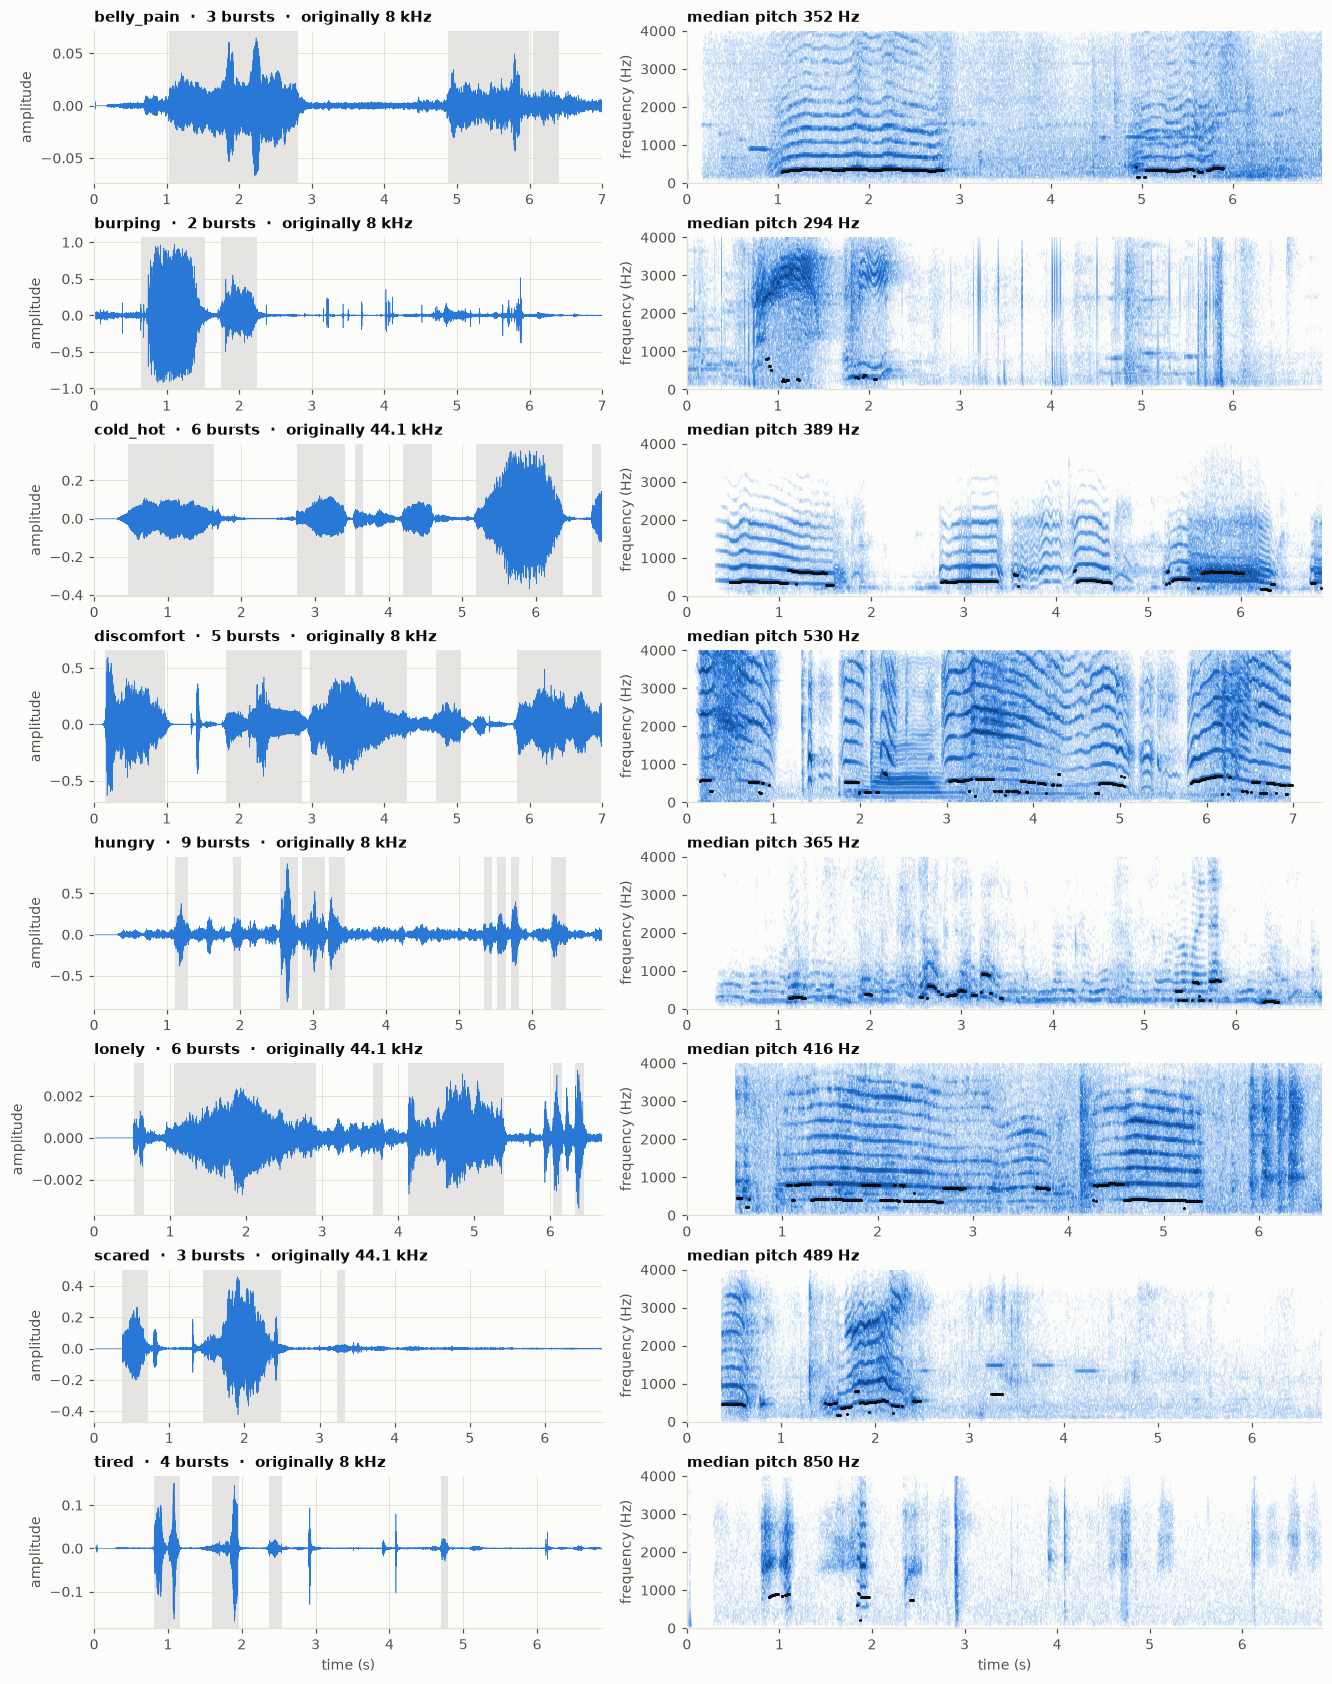

In [2]:
examples = idx.groupby("label").sample(1, random_state=0).set_index("label").loc[CLASSES]

fig, axes = plt.subplots(len(CLASSES), 2, figsize=(12, 1.9 * len(CLASSES)), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1.25]})
for (label, row), (ax_wave, ax_spec) in zip(examples.iterrows(), axes):
    y = load_audio(row["path"])
    level = rms_db(y)
    segs = segments(cry_mask(level))
    f0, _ = yin(y)
    centres = (np.arange(len(level)) * HOP + FRAME / 2) / SR

    ax_wave.plot(np.arange(len(y)) / SR, y, color=viz.BLUE, lw=0.4)
    for start, stop in segs:
        ax_wave.axvspan(centres[start], centres[stop - 1], color=viz.GREY, alpha=0.2, lw=0)
    ax_wave.set_title(f"{label}  ·  {len(segs)} bursts  ·  originally {row['sample_rate'] / 1000:g} kHz")
    ax_wave.set_xlim(0, len(y) / SR)
    ax_wave.set_ylabel("amplitude")

    viz.spectrogram(ax_spec, y)
    in_cry = segment_mask(segs, len(level))
    ax_spec.plot(centres, np.where(in_cry, f0, np.nan), ".", color=viz.INK, ms=2)
    ax_spec.set_title(f"median pitch {np.nanmedian(np.where(in_cry, f0, np.nan)):.0f} Hz")
    for ax in (ax_wave, ax_spec):
        if label != CLASSES[-1]:
            ax.set_xlabel("")
axes[-1, 0].set_xlabel("time (s)")
plt.show()

## 2. Descriptors for every clip

| descriptor | meaning |
|---|---|
| `cry_fraction` | share of the clip inside cry bursts |
| `bursts_per_s` | number of cry bursts per second |
| `burst_s` | median burst length (s) |
| `pause_s` | median pause between bursts (s); missing if the clip has a single burst |
| `voiced_fraction` | share of cry frames that have a pitch |
| `f0_median_hz` | median pitch over voiced cry frames (needs at least 10 voiced frames) |
| `f0_iqr_st` | pitch spread: interquartile range in semitones (12 semitones = one octave) |
| `centroid_hz` | median spectral centroid over cry frames, a measure of how bright or harsh the sound is |

Absolute loudness is left out on purpose: it depends on the phone and its distance from the baby,
not on the baby.

The same loop also stores each clip's average spectrum over its cry frames (used in section 5).

In [3]:
rows, spectra = [], []
for path in idx["path"]:
    y = load_audio(path)
    rows.append(describe(y))
    freqs, P = power_spectrum(y)
    in_cry = segment_mask(segments(cry_mask(rms_db(y))), len(P))
    s = 10 * np.log10(P[in_cry if in_cry.any() else slice(None)].mean(axis=0) + 1e-12)
    spectra.append(s - s.mean())            # spectral shape only: overall loudness removed

DESCRIPTORS = list(rows[0])
desc = pd.concat([idx, pd.DataFrame(rows).astype(float)], axis=1)
desc[DESCRIPTORS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cry_fraction,479.0,0.48,0.19,0.06,0.33,0.48,0.64,1.00
bursts_per_s,479.0,0.80,0.36,0.14,0.57,0.73,1.01,2.18
burst_s,479.0,0.67,0.80,0.12,0.29,0.47,0.77,6.98
pause_s,464.0,0.53,0.57,0.04,0.23,0.36,0.60,4.71
voiced_fraction,479.0,0.69,0.23,0.01,0.56,0.74,0.87,1.00
f0_median_hz,476.0,440.06,104.91,157.01,380.76,420.62,483.41,852.91
f0_iqr_st,476.0,5.48,3.97,0.09,2.35,4.04,7.69,20.80
centroid_hz,479.0,1105.64,521.27,242.95,701.46,987.89,1423.57,2871.09


In [4]:
# How often does pitch tracking find little or no pitch?
low_voicing = desc["voiced_fraction"] < 0.1
print(f"no pitch estimate (fewer than 10 voiced cry frames): {desc['f0_median_hz'].isna().sum()} clips")
print(f"voiced in under 10% of cry frames: {low_voicing.sum()} clips")
pd.crosstab(desc["label"], low_voicing.map({False: "voiced >= 10%", True: "voiced < 10%"}))

no pitch estimate (fewer than 10 voiced cry frames): 3 clips
voiced in under 10% of cry frames: 15 clips


voiced_fraction,voiced < 10%,voiced >= 10%
label,,
belly_pain,0,16
burping,1,8
cold_hot,0,7
discomfort,0,21
hungry,8,374
lonely,0,11
scared,1,4
tired,5,23


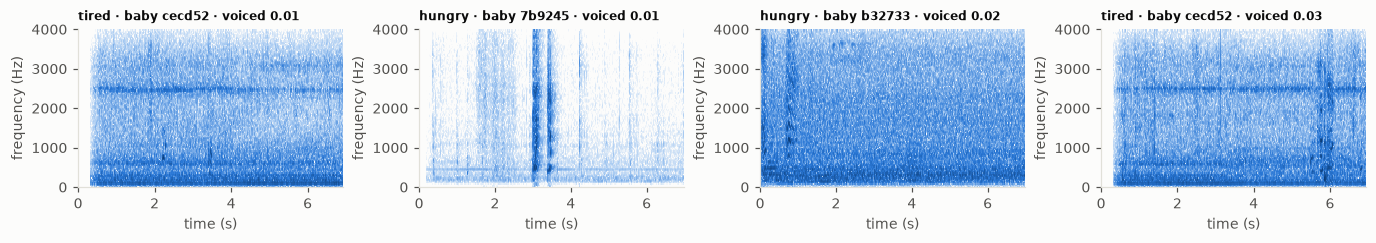

In [5]:
# The least-voiced clips: what are they?
quiet = desc.nsmallest(4, "voiced_fraction")
fig, axes = viz.small_multiples(4, ncols=4, panel=(3.1, 2.1))
for ax, (_, row) in zip(axes, quiet.iterrows()):
    viz.spectrogram(ax, load_audio(row["path"]))
    ax.set_title(f"{row['label']} · baby {row['source'][:6]} · voiced {row['voiced_fraction']:.2f}", fontsize=8)
plt.show()

## 3. One point per baby

Each dot below is one baby within one class: the median of that baby's clips. A baby whose
clips carry two different labels gives one dot to each class. The black tick is the class median
and the dashed grey line is the median over all dots. The number after each class name is the
number of babies with a value.

label   belly_pain  burping  cold_hot  discomfort  hungry  lonely  scared  tired
babies           7        8         3          14     205       8       4     17


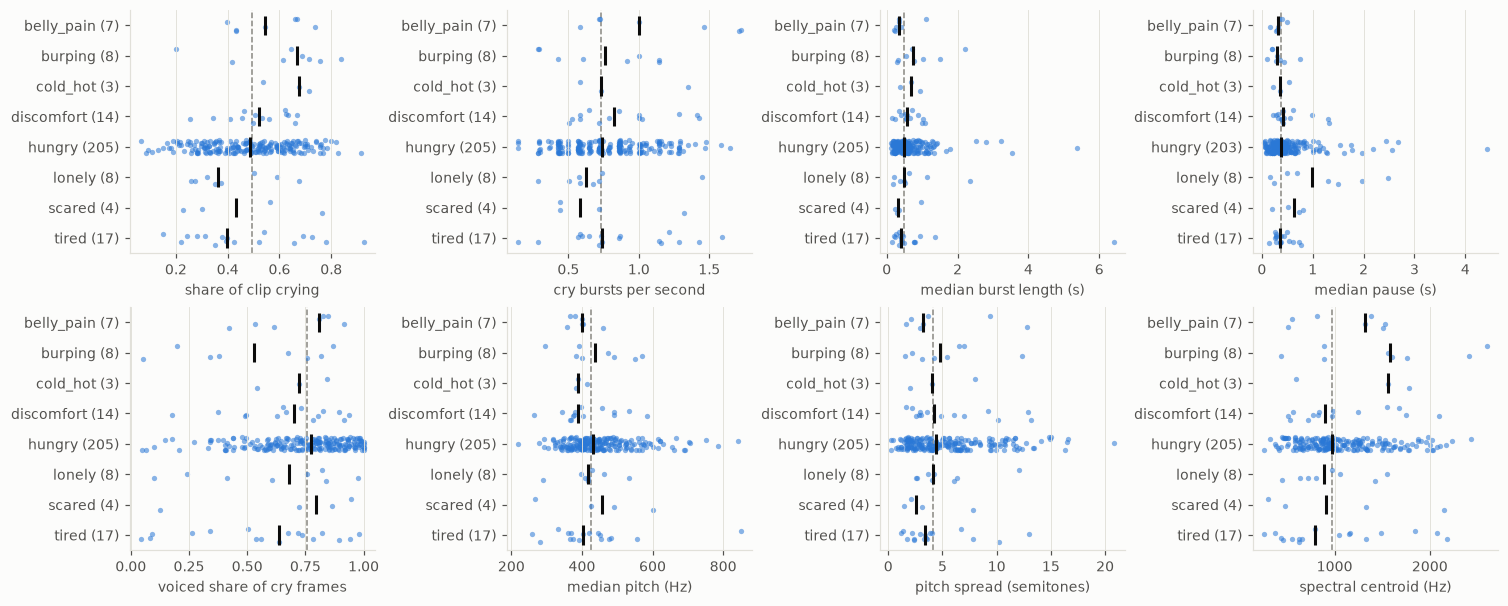

In [6]:
LABELS = {
    "cry_fraction": "share of clip crying", "bursts_per_s": "cry bursts per second",
    "burst_s": "median burst length (s)", "pause_s": "median pause (s)",
    "voiced_fraction": "voiced share of cry frames", "f0_median_hz": "median pitch (Hz)",
    "f0_iqr_st": "pitch spread (semitones)", "centroid_hz": "spectral centroid (Hz)",
}
baby = desc.groupby(["label", "source"], as_index=False)[DESCRIPTORS].median()
print(baby.groupby("label").size().reindex(CLASSES).rename("babies").to_frame().T.to_string())

fig, axes = viz.small_multiples(len(DESCRIPTORS), ncols=4, panel=(3.4, 2.7))
for ax, d in zip(axes, DESCRIPTORS):
    viz.strip_by_class(ax, baby, d)
    ax.set_xlabel(LABELS[d])
plt.show()

## 4. Do the classes differ? Tests on per-baby values

- **Across all 8 classes:** Kruskal–Wallis test (compares ranks, so no normality is assumed). The
  effect size ε² is roughly the share of rank variance explained by the class: 0 means none, 1 means all.
- **Hungry vs the rest:** Mann–Whitney test. For the rest, each baby's non-hungry clips are pooled
  into one value. The rank-biserial r runs from −1 to 1; a positive r means hungry babies tend to
  have higher values.
- 8 descriptors means 8 tests per family, so p-values are Holm-corrected within each family.

Five classes have only 3–8 babies, so these tests have little power for them. A significant
Kruskal–Wallis result is driven mostly by the larger classes.

In [7]:
def holm(p):
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adjusted, running = np.empty_like(p), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adjusted[i] = min(running, 1.0)
    return adjusted


rest = desc[desc["label"] != "hungry"].groupby("source")[DESCRIPTORS].median()
hungry = baby[baby["label"] == "hungry"].set_index("source")[DESCRIPTORS]

rows = []
for d in DESCRIPTORS:
    groups = [baby.loc[baby["label"] == c, d].dropna() for c in CLASSES]
    H, p_kw = kruskal(*groups)
    n, k = sum(map(len, groups)), len(groups)
    h, r_ = hungry[d].dropna(), rest[d].dropna()
    U, p_mw = mannwhitneyu(h, r_, alternative="two-sided")
    rows.append({"descriptor": d, "KW eps2": (H - k + 1) / (n - k), "KW p": p_kw,
                 "hungry median": h.median(), "rest median": r_.median(),
                 "hungry babies": len(h), "rest babies": len(r_),
                 "rank-biserial r": 2 * U / (len(h) * len(r_)) - 1, "MW p": p_mw})
tests = pd.DataFrame(rows).set_index("descriptor")
tests.insert(2, "KW p (Holm)", holm(tests["KW p"]))
tests["MW p (Holm)"] = holm(tests["MW p"])
pvals = ["KW p", "KW p (Holm)", "MW p", "MW p (Holm)"]
tests.round(3).astype(object).assign(**{c: tests[c].map("{:.2g}".format) for c in pvals})

,KW eps2,KW p,KW p (Holm),hungry median,rest median,hungry babies,rest babies,rank-biserial r,MW p,MW p (Holm)
descriptor,,,,,,,,,,
cry_fraction,0.014,0.16,1,0.486,0.522,205,51,-0.074,0.41,1
bursts_per_s,0.0,0.42,1,0.737,0.718,205,51,-0.026,0.77,1
burst_s,0.003,0.36,1,0.5,0.445,205,51,-0.001,0.99,1
pause_s,0.01,0.22,1,0.375,0.4,203,51,-0.06,0.51,1
voiced_fraction,0.013,0.17,1,0.774,0.733,205,51,0.184,0.042,0.3
f0_median_hz,0.005,0.31,1,432.583,401.815,205,51,0.19,0.036,0.29
f0_iqr_st,-0.014,0.84,1,4.434,3.476,205,51,0.099,0.28,1
centroid_hz,-0.006,0.6,1,968.637,888.369,205,51,0.096,0.29,1


## 5. Average spectrum per class

Each clip's spectrum is averaged over its cry frames and shifted so that its mean is 0 dB, which
keeps the shape and removes loudness. Spectra are averaged per baby first, then over the babies
of a class. The grey line in every panel is the average over all babies, for comparison.

Reminder from notebook 01: *cold_hot*, *lonely* and *scared* are 100% originally-44.1 kHz recordings, and
those recordings differ slightly in shape below ~150 Hz and just under 4 kHz. Differences in
those two regions may be the recording format rather than the baby.

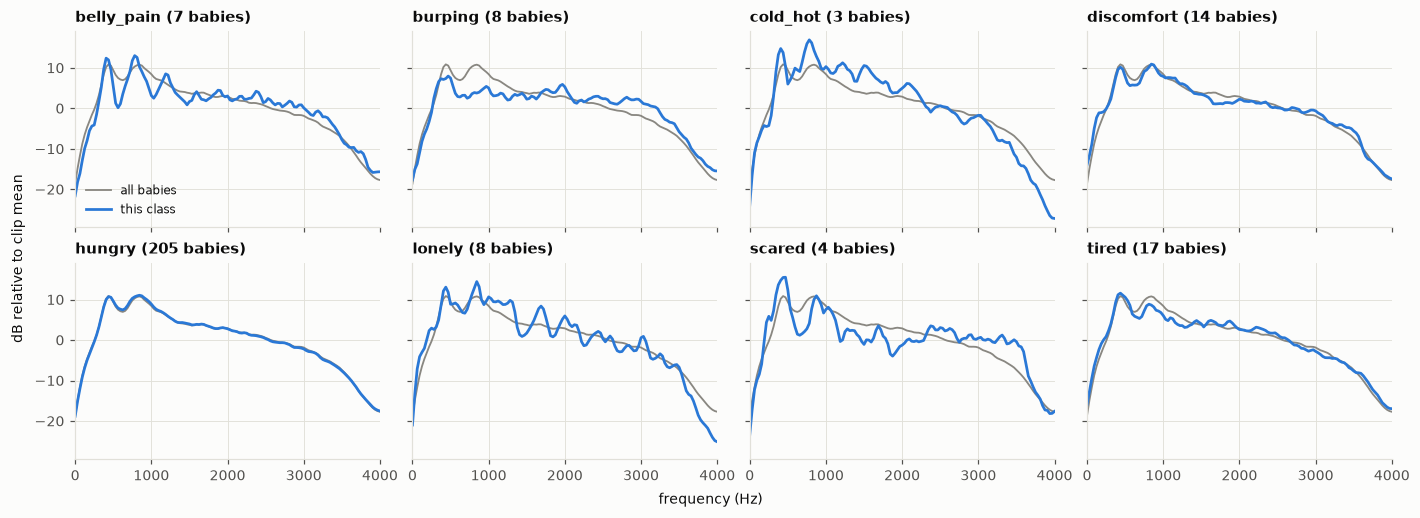

,below 150 Hz,3.5-4 kHz,all clips originally 44.1 kHz
belly_pain,-3.7,1.1,False
burping,-1.0,1.6,False
cold_hot,-1.3,-6.7,True
discomfort,3.7,0.3,False
hungry,-0.3,0.0,False
lonely,2.4,-4.4,True
scared,-2.2,1.9,True
tired,2.3,0.8,False


In [8]:
spec = pd.DataFrame(np.vstack(spectra), columns=freqs)
baby_spec = spec.groupby([idx["label"], idx["source"]]).median()
overall = baby_spec.mean()

fig, axes = viz.small_multiples(len(CLASSES), ncols=4, panel=(3.2, 2.3), sharex=True, sharey=True)
for ax, c in zip(axes, CLASSES):
    ax.plot(freqs, overall, color=viz.GREY, lw=1.2, label="all babies")
    ax.plot(freqs, baby_spec.loc[c].mean(), color=viz.BLUE, lw=1.8, label="this class")
    ax.set_title(f"{c} ({len(baby_spec.loc[c])} babies)")
    ax.set_xlim(0, SR / 2)
axes[0].legend(loc="lower left", fontsize=8)
fig.supxlabel("frequency (Hz)", fontsize=9)
fig.supylabel("dB relative to clip mean", fontsize=9)
plt.show()

# Class minus all-baby average, in the two bands where the recording formats differ (notebook 01)
bands = {"below 150 Hz": freqs < 150, "3.5-4 kHz": freqs >= 3500}
offsets = pd.DataFrame({name: [(baby_spec.loc[c].mean() - overall)[mask].mean() for c in CLASSES]
                        for name, mask in bands.items()}, index=CLASSES)
offsets["all clips originally 44.1 kHz"] = idx.groupby("label")["sample_rate"].apply(lambda s: (s == 44100).all())
offsets.round(1)

## 6. Every baby has its own voice

If a baby's clips are much more alike than clips from different babies, then a model scored on
a baby it was trained on gets credit for recognising the baby, not the need. The intra-class
correlation (ICC) measures this. It is the share of the variation in a descriptor that lies
*between* babies: 0 means knowing the baby tells you nothing, 1 means all of a baby's clips are
identical.

It is computed within *hungry* only, using babies with at least 2 hungry clips, so the label is
held fixed. The 95% interval resamples babies (1000 bootstrap draws).

In [9]:
def icc1(groups):
    """One-way random-effects ICC(1) from a list of per-baby arrays of unequal size."""
    groups = [g for g in groups if len(g) >= 2]
    n_i = np.array([len(g) for g in groups])
    means = np.array([g.mean() for g in groups])
    x = np.concatenate(groups)
    N, G = len(x), len(groups)
    msb = (n_i * (means - x.mean()) ** 2).sum() / (G - 1)
    msw = sum(((g - g.mean()) ** 2).sum() for g in groups) / (N - G)
    k0 = (N - (n_i ** 2).sum() / N) / (G - 1)
    return (msb - msw) / (msb + (k0 - 1) * msw)


hu = desc[desc["label"] == "hungry"]
multi = hu[hu.groupby("source")["source"].transform("size") >= 2]
rng = np.random.default_rng(0)
rows = []
for d in DESCRIPTORS:
    groups = [v[~np.isnan(v)] for v in multi.groupby("source")[d].apply(np.asarray)]
    boot = [icc1([groups[j] for j in rng.integers(0, len(groups), len(groups))]) for _ in range(1000)]
    rows.append({"descriptor": d, "ICC": icc1(groups),
                 "95% low": np.percentile(boot, 2.5), "95% high": np.percentile(boot, 97.5)})
print(f"hungry babies with 2+ clips: {multi['source'].nunique()}, clips: {len(multi)}")
pd.DataFrame(rows).set_index("descriptor").round(2)

hungry babies with 2+ clips: 93, clips: 270


,ICC,95% low,95% high
descriptor,,,
cry_fraction,0.29,0.12,0.43
bursts_per_s,0.27,0.15,0.38
burst_s,0.16,0.02,0.33
pause_s,0.12,-0.04,0.29
voiced_fraction,0.35,0.20,0.49
f0_median_hz,0.26,0.10,0.42
f0_iqr_st,0.29,0.12,0.44
centroid_hz,0.43,0.28,0.59


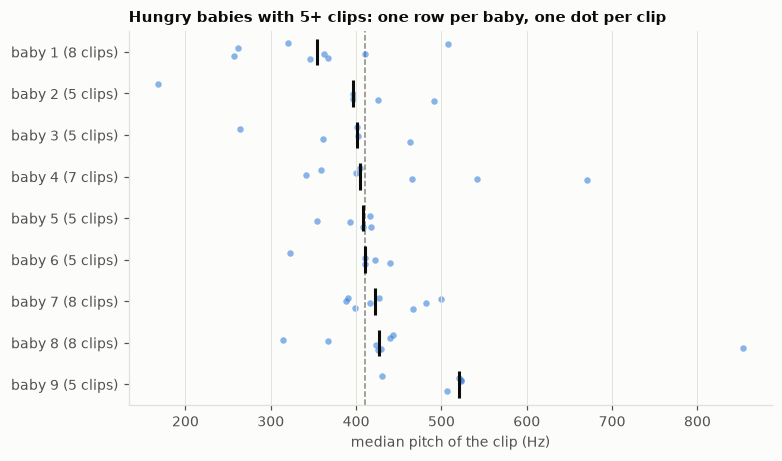

In [10]:
# Median pitch of each clip, for the hungry babies with the most clips
top = multi.groupby("source").size().loc[lambda s: s >= 5].index
sub = multi[multi["source"].isin(top)]
order = sub.groupby("source")["f0_median_hz"].median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(7, 0.32 * len(order) + 1.2), constrained_layout=True)
viz.strip_by_class(ax, sub, "f0_median_hz", by="source", order=order, size=18)
counts = sub.dropna(subset=["f0_median_hz"]).groupby("source").size()
ax.set_yticks(range(len(order)), [f"baby {i + 1} ({counts[b]} clips)" for i, b in enumerate(order)])
ax.set_xlabel("median pitch of the clip (Hz)")
ax.set_title(f"Hungry babies with 5+ clips: one row per baby, one dot per clip")
plt.show()

## 7. Findings

All numbers below are printed by the cells above.

1. **The descriptors work on these recordings, but only after adapting to them.** Many clips are
   noisy phone recordings with a steady low hum, and some are very quiet. With textbook settings
   the pitch tracker missed most clearly harmonic cry frames, and the segmenter missed quiet cries,
   so the thresholds are relative to each clip (section 1, and the comments in
   `src/descriptors.py`). In the typical clip, the baby cries for 48% of the 7 s, in 0.73 bursts per
   second with a median burst of 0.47 s. The median pitch is 421 Hz (middle half of clips:
   381–483 Hz), and the pitch tracks follow the lowest harmonic on the spectrograms.
2. **Some clips contain little or no crying.** 15 clips are voiced in under 10% of their cry
   frames, and 3 have no pitch estimate at all. The least-voiced ones are steady noise with no
   visible cry. Three of the 5 such *tired* clips come from a single baby. They are kept, because
   the parent's label is still the label, but they add label noise that no model can resolve and
   will be checked again in the error analysis (06).
3. **No single descriptor separates the 8 classes.** The Kruskal–Wallis effect sizes are at most
   ε² = 0.014, and every Holm-corrected p-value is 1. Hungry vs the rest gives the largest
   differences in voiced share (median 0.774 vs 0.733, r = 0.18) and pitch (433 vs 402 Hz,
   r = 0.19). Their uncorrected p-values (0.042, 0.036) do not survive the correction (0.30, 0.29).
   In the strip plots the class medians sit well inside the spread of individual babies.
4. **Babies differ more than classes do.** Among 93 hungry babies with 2+ clips (270 clips), the
   ICC is 0.12–0.35 for most descriptors and 0.43 (95% interval 0.28–0.59) for spectral centroid,
   while the class effect sizes are around 0.01. A model allowed to see the same baby in training
   and test would score points for recognising the baby. This confirms that every split must be
   grouped by baby.
5. **The spectrum may carry the recording format.** The well-populated classes (*hungry*,
   *discomfort*, *tired*) sit on the all-baby average. In the 3.5–4 kHz band, where notebook 01
   found the two formats differ, *cold_hot* and *lonely* (all clips originally 44.1 kHz) are 6.7 and
   4.4 dB below the average, while every other class is within 2 dB. *scared*, also all 44.1 kHz, is
   not (+1.9 dB), and below 150 Hz there is no consistent pattern. So the evidence is suggestive,
   not conclusive. Notebook 03 tests directly whether the features can predict the original
   format, and band-limits them if they can. The small classes' curves are bumpy because they
   average only 3–8 babies.
6. **What this means for modelling.** Any usable signal has to come from combinations of
   features or finer spectral detail, not from a single obvious cue. With label noise and 3–8
   babies in the small classes, modest scores are the realistic expectation. The bar to clear is
   still the always-hungry baseline (balanced accuracy 0.125, macro-F1 0.111).